# 03｜ViViT 样本外因子评价与回测

请使用 `ViT Factor Eval (Alphalens/Pyfolio)` 内核。三种口径都先在完整 T 日预测截面固定五分位，RankIC 使用完整价格有效截面。默认采用口径 2：T→T+k，不使用未来的 `can_enter_t1` 状态过滤；口径 1 和口径 3可显式选择。每次评价自动生成完整因子覆盖池的全市场等权基准及相对绩效指标。


## 步骤 1：选择 ViViT run、回测口径与可选模型基准

`FOLDER_NAME` 指向本次要评价的 ViViT run，`PREDICTION_COLUMN` 独立选择该 run 的回测信号。`BASELINE_RUN_NAME` 与 `BASELINE_PREDICTION_COLUMN` 指定对比信号；基准 run 设为 `None` 时跳过模型间比较。模型基准与自动生成的全市场等权收益基准不是一回事。


In [1]:
from pathlib import Path
import sys
from IPython.display import display

CURRENT_DIR = Path.cwd().resolve()
VIVIT_DIR = CURRENT_DIR if (CURRENT_DIR / "stage08_factor_evaluation.py").exists() else CURRENT_DIR / "ViViT"
if not (VIVIT_DIR / "stage08_factor_evaluation.py").exists():
    raise FileNotFoundError("无法定位 ViViT/stage08_factor_evaluation.py")
VIVIT_DATA_ROOT = VIVIT_DIR / "data"
REFERENCE_DATA_ROOT = VIVIT_DIR.parent / "ViT" / "data"
if str(VIVIT_DIR) not in sys.path:
    sys.path.insert(0, str(VIVIT_DIR))

FOLDER_NAME = "dual_tower_barra_residual"  # 要评价的 ViViT run
BASELINE_RUN_NAME = "baseline_barra_residual"  # 可选模型 run；None 表示跳过模型间比较
# 可选预测列：prediction_ensemble、prediction_ensemble_raw、prediction_ensemble_unprojected、
# prediction_ensemble_projected、prediction_ensemble_alpha、prediction_ensemble_style、
# prediction_ensemble_total_return。No.6 默认主列等于 Alpha；Style/Total 可单独评价且产物隔离。
# No.5 回测投影前模型 raw score 时选择 prediction_ensemble_unprojected。
PREDICTION_COLUMN = "prediction_ensemble"
# 基准 run 可独立选择列；普通 baseline 默认使用 prediction_ensemble。
BASELINE_PREDICTION_COLUMN = "prediction_ensemble"

BACKTEST_MODE = "mode2_t_no_filter"
# BACKTEST_MODE 全部可选值：
# "mode1_t_with_t1_filter"：T→T+k；五分位固定后，仅组合收益和换手使用 can_enter_t1
# "mode2_t_no_filter"：T→T+k；不使用未来状态过滤（默认）
# "mode3_t1_no_filter"：T+1→T+1+k；不使用未来状态过滤（1/5/10D 终点为 T+2/T+6/T+11）

print({
    "ViViT目录": str(VIVIT_DIR),
    "待评价run": FOLDER_NAME,
    "对比模型run": BASELINE_RUN_NAME,
    "待评价预测列": PREDICTION_COLUMN,
    "基准预测列": BASELINE_PREDICTION_COLUMN,
    "回测口径": BACKTEST_MODE,
    "收益周期": (1, 5, 10),
    "分位数": 5,
    "自动市场基准": "完整因子覆盖池全市场等权",
})


{'ViViT目录': '/root/autodl-tmp/ViViT', '待评价run': 'dual_tower_barra_residual', '对比模型run': 'baseline_barra_residual', '待评价预测列': 'prediction_ensemble', '基准预测列': 'prediction_ensemble', '回测口径': 'mode2_t_no_filter', '收益周期': (1, 5, 10), '分位数': 5, '自动市场基准': '完整因子覆盖池全市场等权'}


## 步骤 2：只读审计评价输入

检查 training/aligned store/dataset/Universe 签名链、2018–2024 预测业务键、2025 空预测，以及所选口径所需的交易日历覆盖。口径 3 会检查至 T+11；本步骤不创建评价产物。


In [2]:
from stage08_factor_evaluation import audit_evaluation_inputs

input_audit = audit_evaluation_inputs(
    run_name=FOLDER_NAME,
    vivit_data_root=VIVIT_DATA_ROOT,
    reference_data_root=REFERENCE_DATA_ROOT,
    prediction_column=PREDICTION_COLUMN,
    backtest_mode=BACKTEST_MODE,
)
display(input_audit)
print(input_audit.attrs)


,year,prediction_rows,universe_rows,dates,first_date,last_date,can_enter_t1_rows,status
0,2018,796559,796559,243,20180102,20181228,782135,passed
1,2019,861870,861870,244,20190102,20191231,846521,passed
2,2020,916587,916587,243,20200102,20201231,896062,passed
3,2021,1027544,1027544,242,20210104,20211231,1008898,passed
4,2022,1120684,1120684,242,20220104,20221230,1103117,passed
5,2023,1195010,1195010,242,20230103,20231229,1185236,passed
6,2024,1200893,1200893,242,20240102,20241231,1179595,passed
7,2025,0,0,0,None,None,0,empty_prediction_expected


{'run_name': 'dual_tower_barra_residual', 'model_family': 'ViViT', 'factor_role': 'barra_reversal20_residual', 'source_run_name': 'dual_tower', 'prediction_pattern': 'vivit_predictions.{year}.parquet', 'prediction_column': 'prediction_ensemble', 'last_factor_date': '20241231', 'final_price_date': '20250115', 'backtest_mode': 'mode2_t_no_filter', 'price_start_offset': 0, 'dataset_signature': '7e549f6c4204f6228867617461dd8402bc1868e21b320239cdd8c262ad5f5058', 'universe_signature': '8f19afb3f8f20601cd181b77a033c079cce1fcde518f22e227d2b7299b04fbfe', 'sequence_signature': 'cf1b42d47c6a94c5bea866a2a61725ba9f599930f08c0a18e3d37a793067bace'}


## 步骤 3：执行完整 Alphalens / Pyfolio 评价

结果按预测列隔离保存：默认列写入 `factor_evaluation/`，`prediction_ensemble_unprojected` 写入 `factor_evaluation_unprojected/`，其余可选列也各有独立目录，不会互相覆盖。评价包含 Parquet、累计收益图、最大回撤、Alphalens tear sheet、manifest 和独立实验报告。ViT 数据保持只读。


,year,prediction_rows,can_enter_t1_rows,t1_excluded_rows,dates,first_date,last_date
0,2018,796559,782135,14424,243,20180102,20181228
1,2019,861870,846521,15349,244,20190102,20191231
2,2020,916587,896062,20525,243,20200102,20201231
3,2021,1027544,1008898,18646,242,20210104,20211231
4,2022,1120684,1103117,17567,242,20220104,20221230
5,2023,1195010,1185236,9774,242,20230103,20231229
6,2024,1200893,1179595,21298,242,20240102,20241231


,price_point,available_rows,missing_rows,coverage
0,T,7119147,0,100.000000%
1,T+1,7119085,62,99.999129%
2,T+5,7118790,357,99.994985%
3,T+10,7118262,885,99.987569%


,period,price_start,price_end,formula,samples_checked,max_abs_error
0,1D,T,T+1,adj_close(T+k) / adj_close(T) - 1,25,0.0
1,5D,T,T+5,adj_close(T+k) / adj_close(T) - 1,25,0.0
2,10D,T,T+10,adj_close(T+k) / adj_close(T) - 1,25,0.0


,period,days,mean_ic,median_ic,std_ic,positive_ratio,t_stat,p_value
0,1D,1698,0.038451,0.038575,0.048777,0.777974,32.483232,2.073397e-180
1,5D,1698,0.059442,0.061022,0.050364,0.878681,48.633991,0.000000e+00
2,10D,1698,0.069732,0.069163,0.051023,0.921084,56.315876,0.000000e+00


,year,period,days,mean_ic,median_ic,std_ic,positive_ratio
0,2018,1D,243,0.043058,0.043263,0.051762,0.802469
1,2019,1D,244,0.041820,0.042142,0.038862,0.844262
2,2020,1D,243,0.039752,0.041427,0.047883,0.769547
3,2021,1D,242,0.030456,0.029145,0.040800,0.760331
4,2022,1D,242,0.040789,0.040821,0.048435,0.747934
5,2023,1D,242,0.030804,0.031509,0.049398,0.735537
6,2024,1D,242,0.042424,0.045601,0.060066,0.785124
7,2018,5D,243,0.065345,0.068993,0.047507,0.897119
8,2019,5D,244,0.064926,0.066920,0.045058,0.918033
9,2020,5D,243,0.065070,0.065952,0.054641,0.893004


,quantile,1D,5D,10D
0,1,-0.001253,-0.003672,-0.005723
1,2,0.000059,0.001112,0.002293
2,3,0.000421,0.002440,0.004539
3,4,0.000669,0.003213,0.005711
4,5,0.000837,0.003780,0.006661


,period,Q5_minus_Q1_return,standard_error
0,1D,0.002090,0.000085
1,5D,0.007452,0.000208
2,10D,0.012385,0.000294


,Q5 long-only,Q5-Q1 long-short,Equal-weight market
Annual return,0.195720,0.689809,0.005938
Cumulative returns,2.334844,33.291852,0.040701
Annual volatility,0.252951,0.055681,0.248224
Sharpe ratio,0.834040,9.459380,0.148644
Calmar ratio,0.593391,18.403256,0.015853
Stability,0.888108,0.995337,0.312879
Max drawdown,-0.329834,-0.037483,-0.374596
Omega ratio,1.158625,4.760619,1.026947
Sortino ratio,1.154438,20.930208,0.200728
Skew,-0.535791,-0.226777,-0.498054


,portfolio,benchmark,observations,portfolio_annual_return,benchmark_annual_return,annual_excess_return,annual_tracking_error,information_ratio
0,Q5 long-only,Equal-weight market,1698,0.195720,0.005938,0.189782,0.028609,6.084637
1,Q5-Q1 long-short,Equal-weight market,1698,0.689809,0.005938,0.683870,0.261331,1.874297


,item,value
0,A2 run,dual_tower_barra_residual
1,prediction years,"(2018, 2019, 2020, 2021, 2022, 2023, 2024)"
2,backtest mode,mode2_t_no_filter
3,T-day grouping rows before price filter,"7,119,147"
4,T-day grouping rows after price filter / IC rows,"7,118,262"
5,portfolio rows after execution filter,"7,118,262"
6,factor grouping policy,T full cross-section before execution filter
7,IC scope,T full cross-section with valid forward prices
8,portfolio scope,full_t_cross_section_no_t1_filter
9,execution mask,none


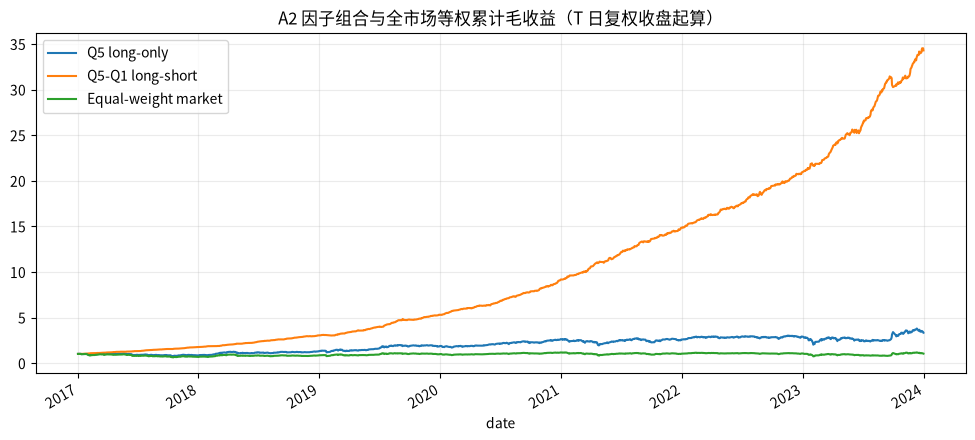

累计收益图：/tmp/vivit_factor_eval_dual_tower_barra_residual_nvt51ctp/quality/runs/dual_tower_barra_residual/factor_evaluation/portfolio_cumulative_returns.png


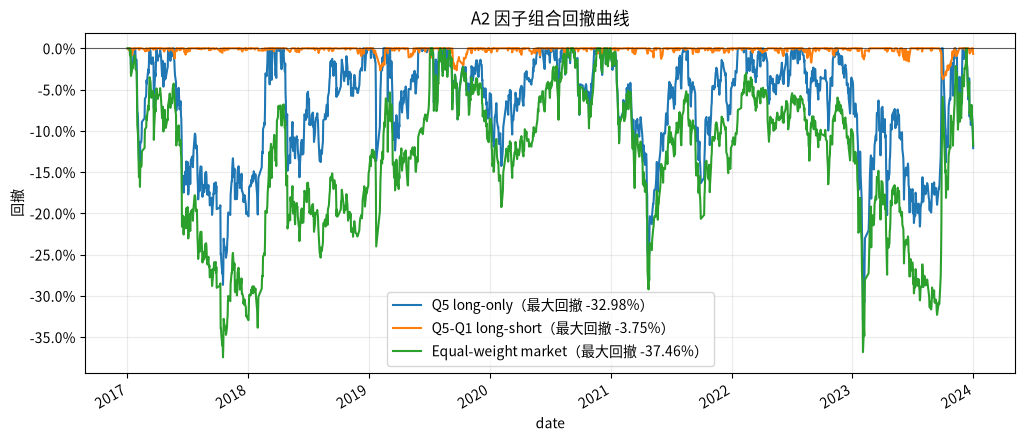

最大回撤图：/tmp/vivit_factor_eval_dual_tower_barra_residual_nvt51ctp/quality/runs/dual_tower_barra_residual/factor_evaluation/pic/portfolio_drawdown.png
Quantiles Statistics


,min,max,mean,std,count,count %
factor_quantile,,,,,,
1,-22.195070,-0.188294,-0.959694,0.986619,1423951,20.004195
2,-0.681909,0.040903,-0.215292,0.150542,1423733,20.001132
3,-0.194690,0.315277,0.082150,0.087444,1423787,20.001891
4,0.135236,0.730674,0.343434,0.115490,1423770,20.001652
5,0.326426,8.035396,0.750710,0.344843,1423021,19.991130


Returns Analysis


,1D,5D,10D
Ann. alpha,0.381,0.248,0.195
beta,-0.027,-0.035,-0.035
Mean Period Wise Return Top Quantile (bps),6.908,4.807,3.958
Mean Period Wise Return Bottom Quantile (bps),-13.993,-10.112,-8.451
Mean Period Wise Spread (bps),20.901,14.932,12.423


<Figure size 640x480 with 0 Axes>

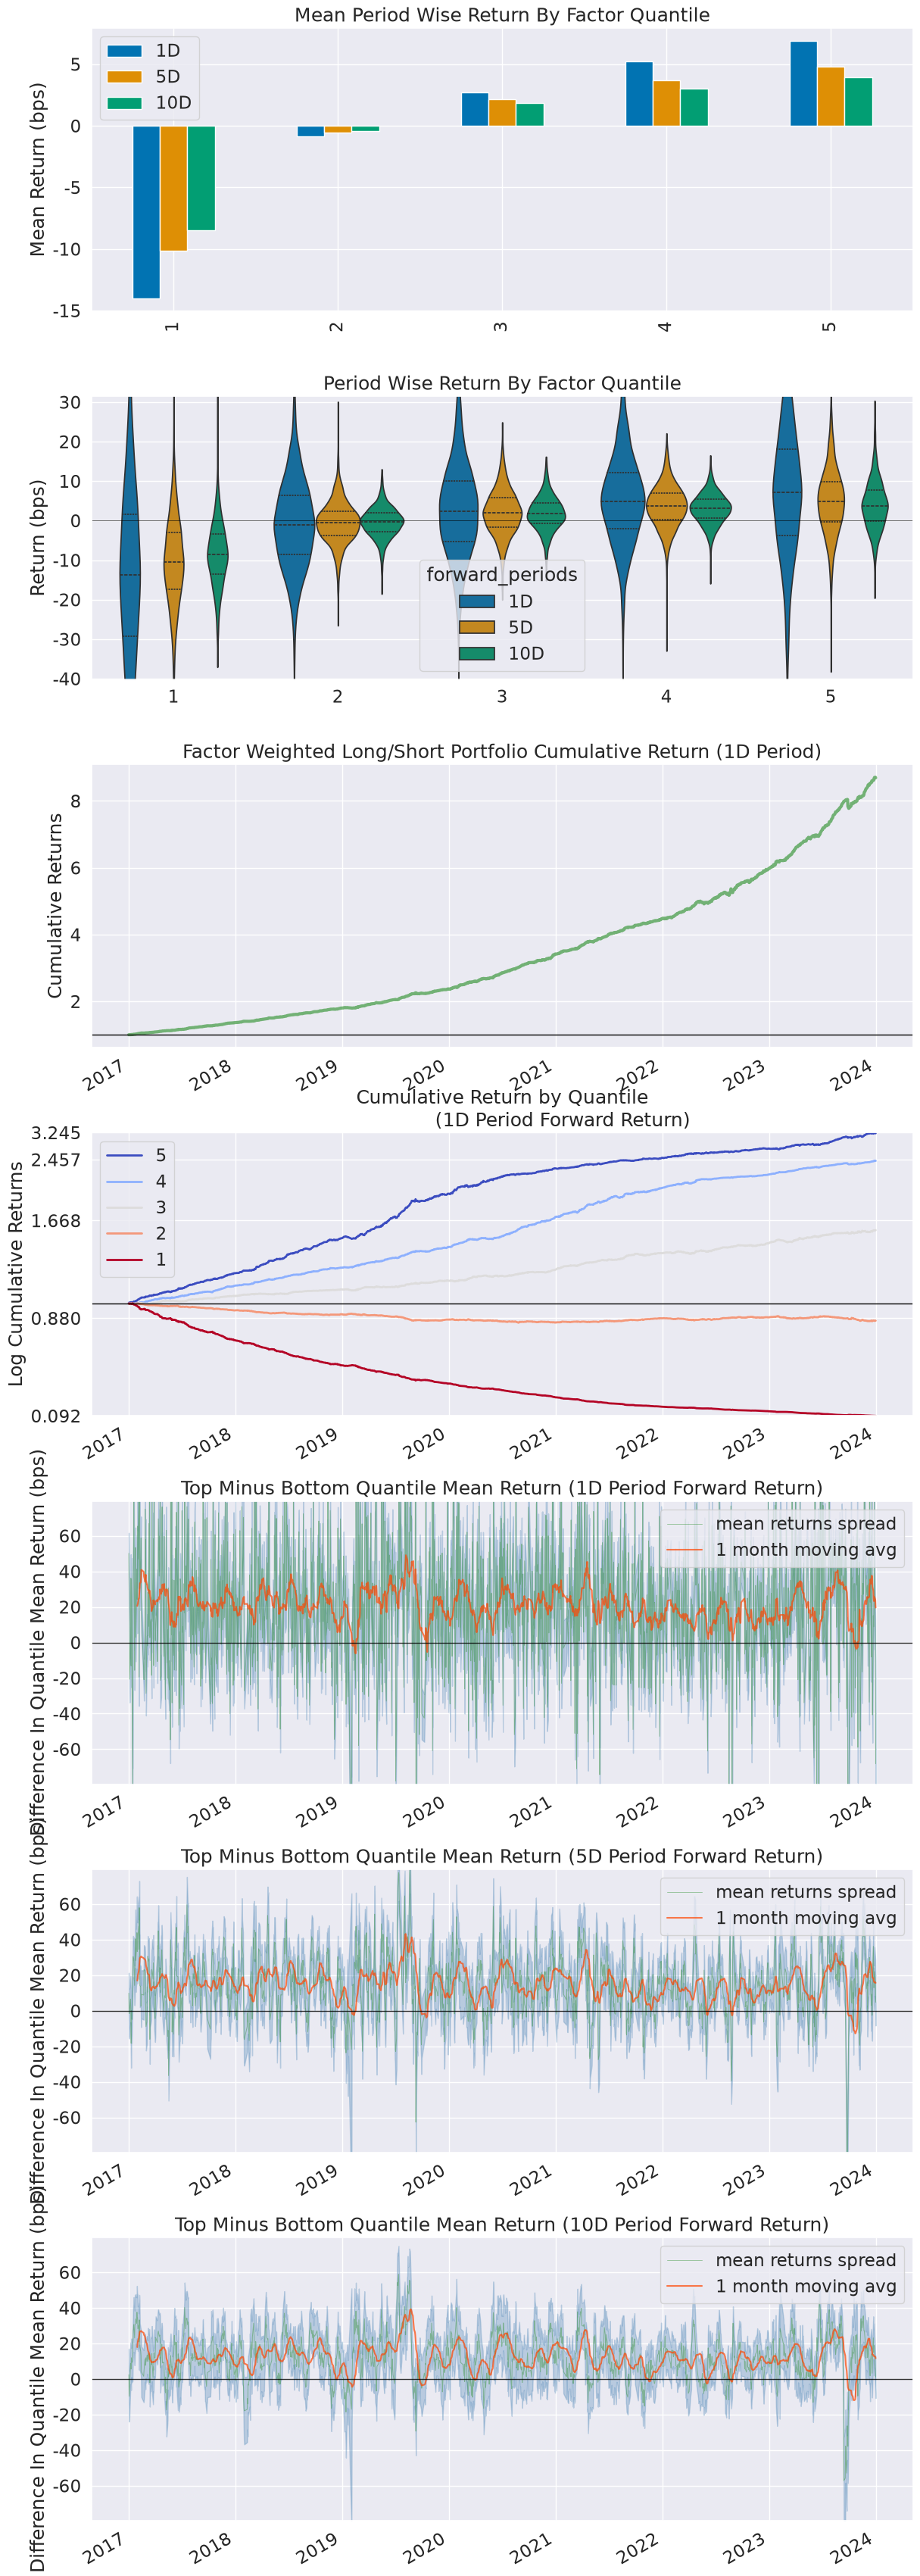

Information Analysis


,1D,5D,10D
IC Mean,0.038,0.059,0.070
IC Std.,0.049,0.050,0.051
Risk-Adjusted IC,0.788,1.180,1.367
t-stat(IC),32.483,48.634,56.316
p-value(IC),0.000,0.000,0.000
IC Skew,-0.149,-0.080,-0.049
IC Kurtosis,0.354,0.377,0.609


/root/autodl-tmp/ViT/.venv-factor-eval/lib/python3.12/site-packages/alphalens/performance.py:118: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  grouper.append(pd.Grouper(freq=by_time))


<Figure size 640x480 with 0 Axes>

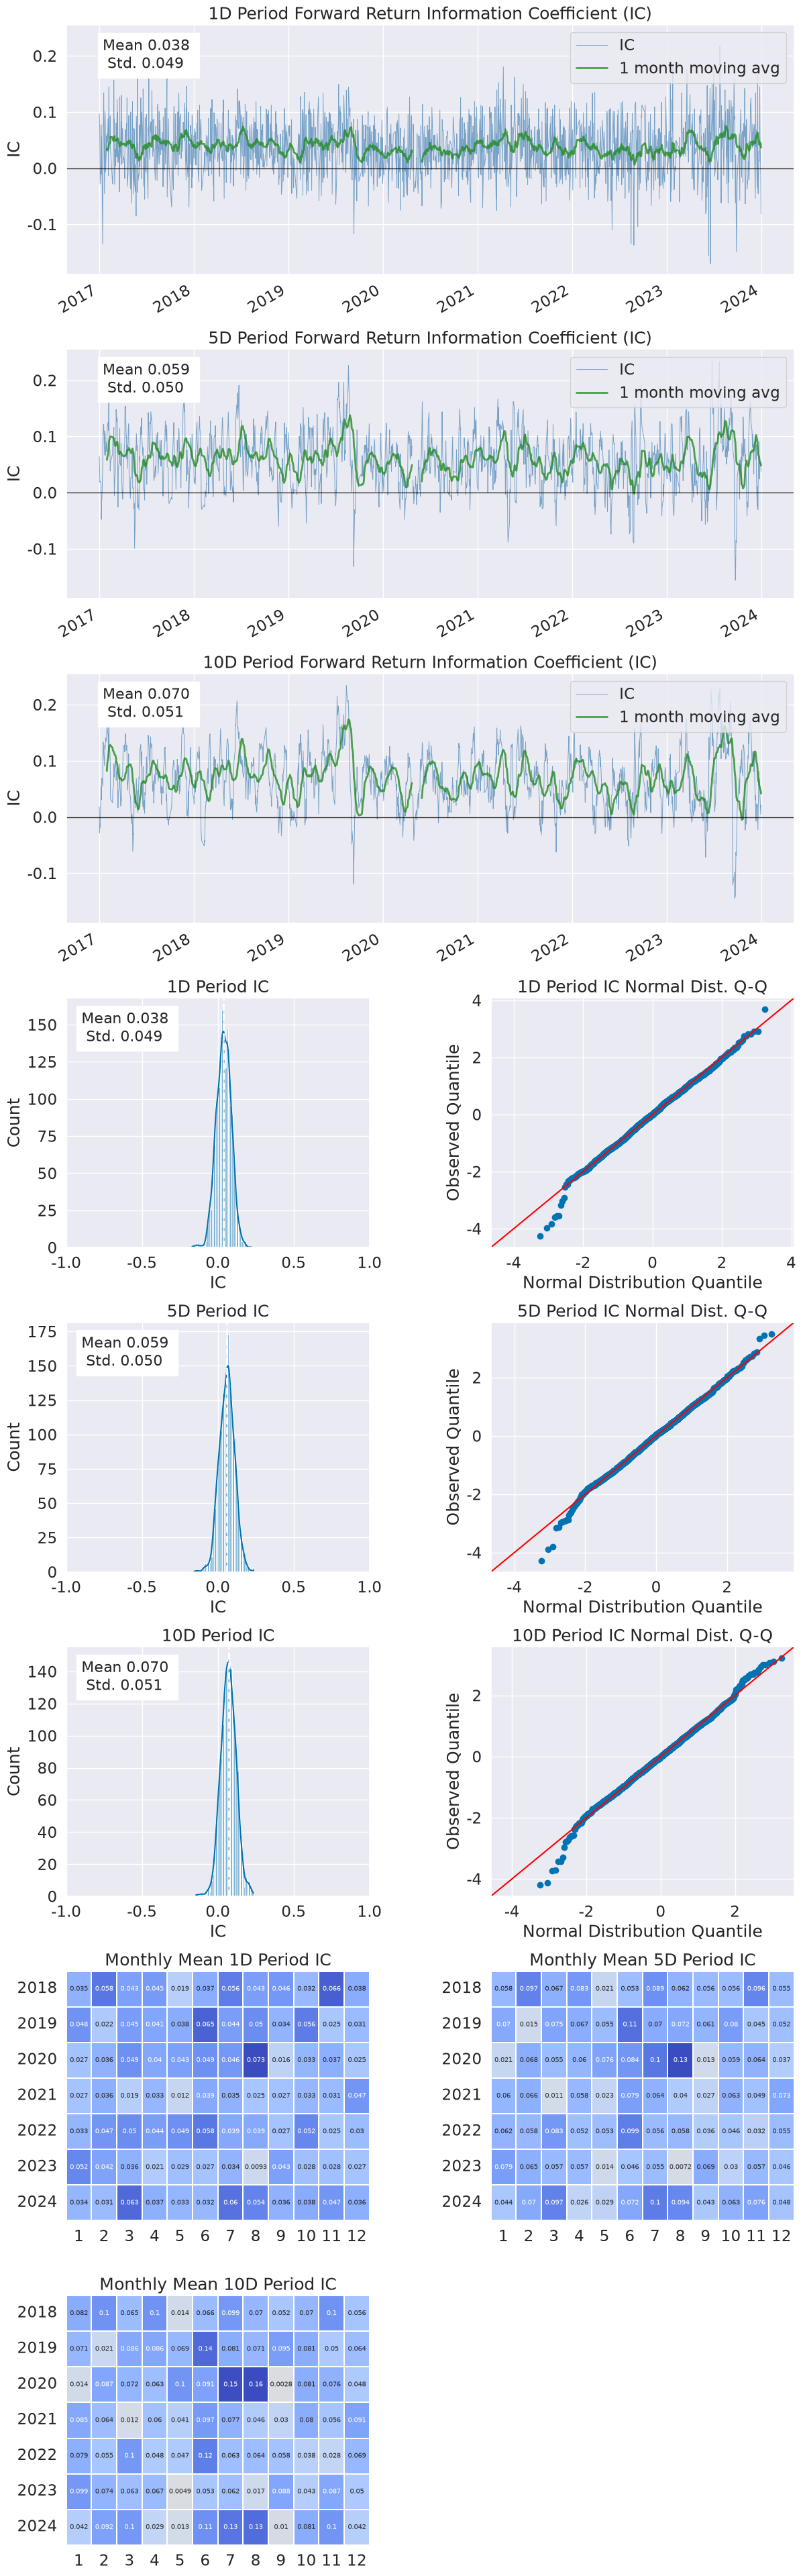

/root/autodl-tmp/ViT/.venv-factor-eval/lib/python3.12/site-packages/alphalens/utils.py:928: UserWarning: Skipping return periods that aren't exact multiples of days.
  warnings.warn(


Turnover Analysis


,1D,5D,10D
Quantile 1 Mean Turnover,0.212,0.313,0.384
Quantile 2 Mean Turnover,0.413,0.547,0.610
Quantile 3 Mean Turnover,0.470,0.596,0.653
Quantile 4 Mean Turnover,0.428,0.557,0.619
Quantile 5 Mean Turnover,0.203,0.302,0.368


,1D,5D,10D
Mean Factor Rank Autocorrelation,0.929,0.839,0.76


<Figure size 640x480 with 0 Axes>

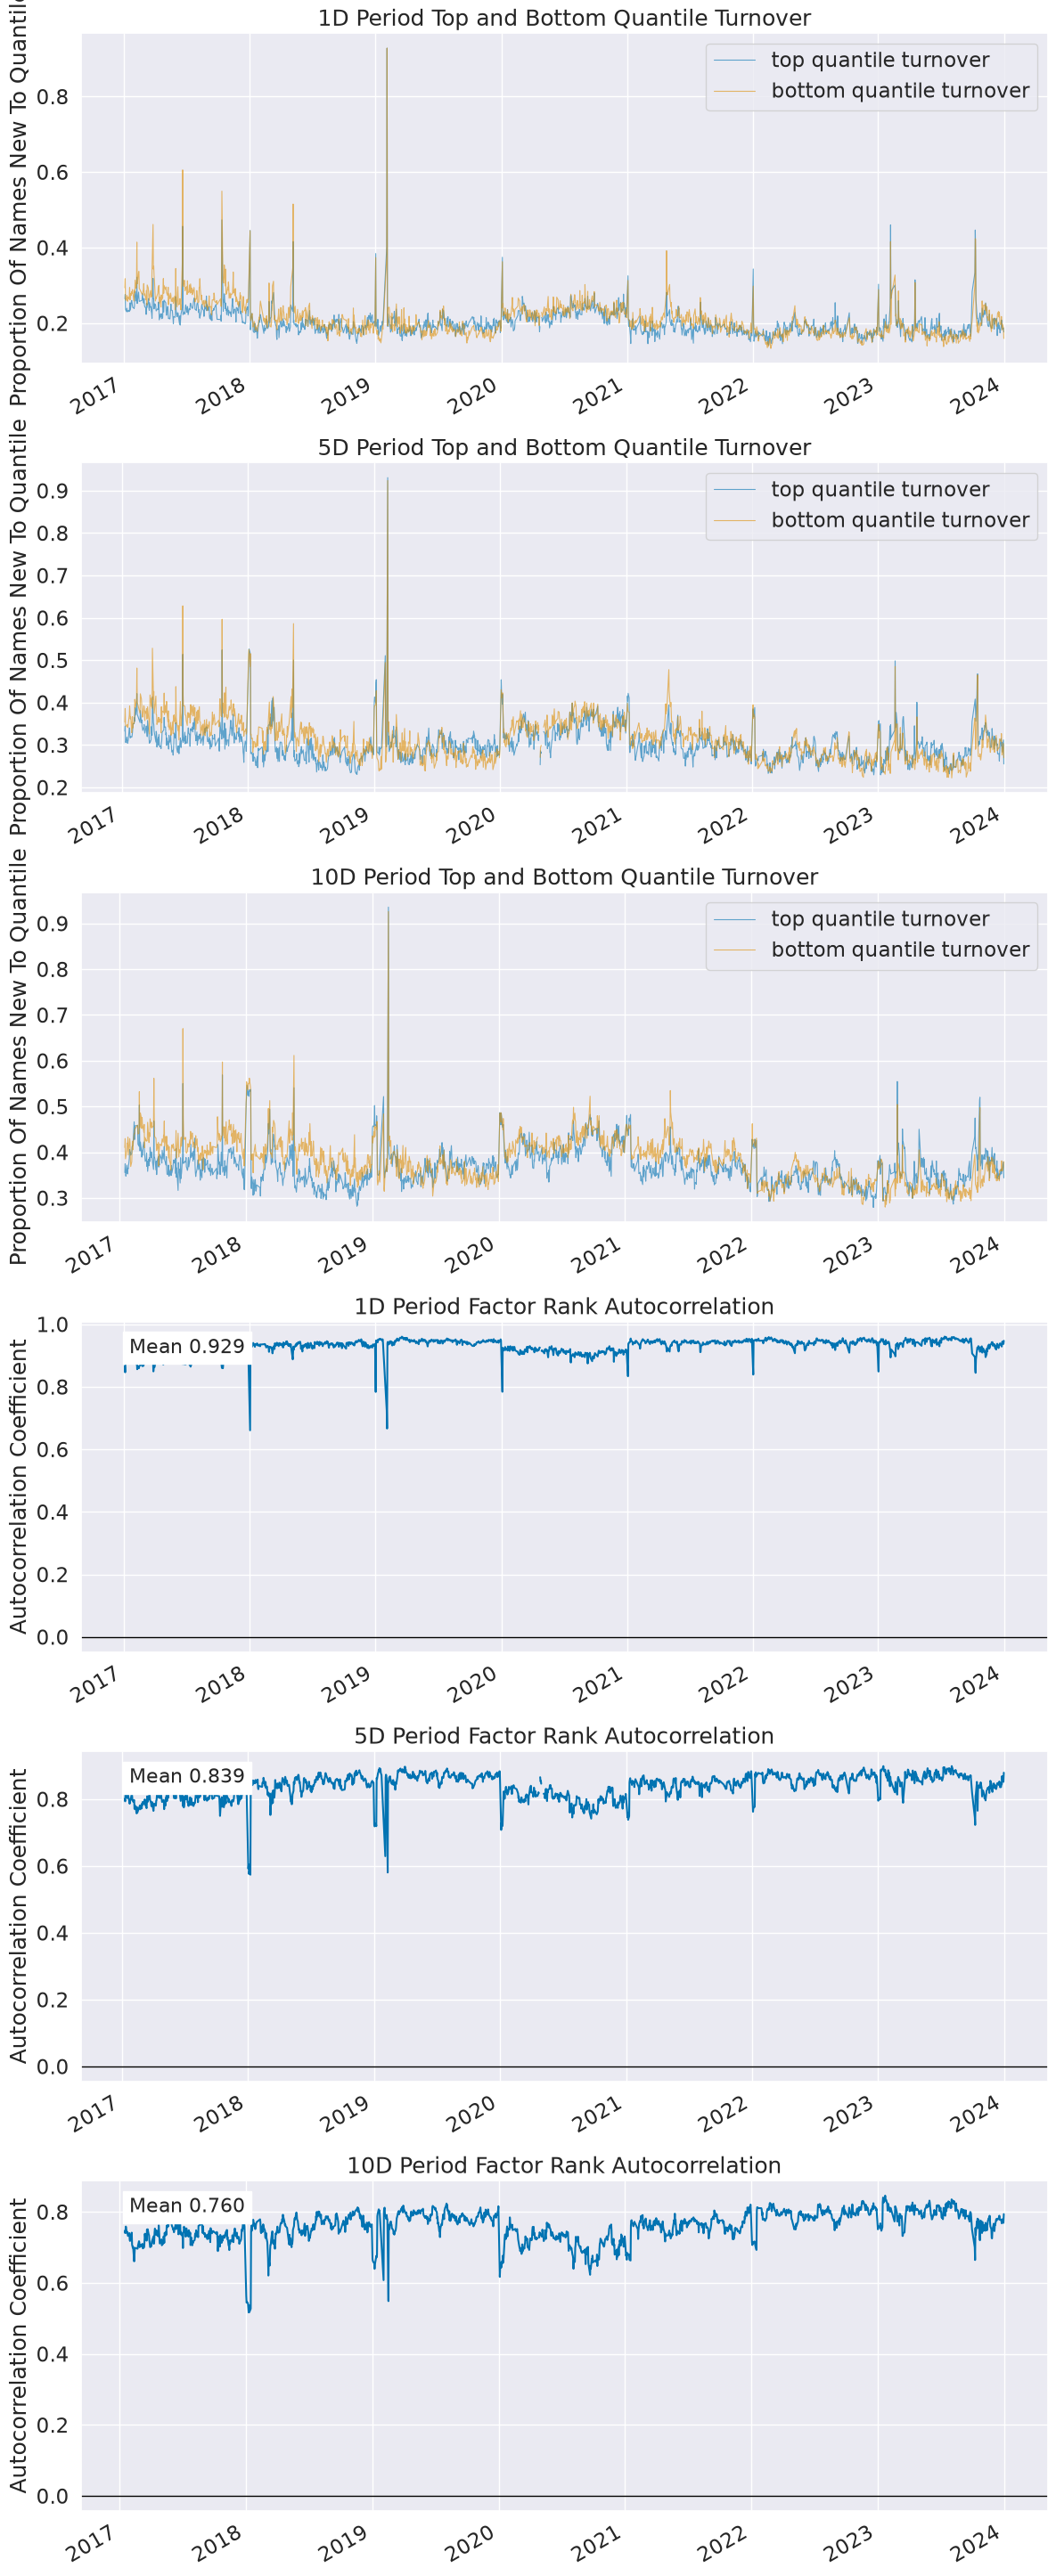

Alphalens tear sheet：/tmp/vivit_factor_eval_dual_tower_barra_residual_nvt51ctp/quality/runs/dual_tower_barra_residual/factor_evaluation/pic
实验报告：/root/autodl-tmp/ViViT/data/quality/runs/dual_tower_barra_residual/EXPERIMENT_REPORT.md
样本外因子评价完成；模式=mode2_t_no_filter，价格起点=T。
实验报告：/root/autodl-tmp/ViViT/data/quality/runs/dual_tower_barra_residual/EXPERIMENT_REPORT.md


,item,value
0,A2 run,dual_tower_barra_residual
1,prediction years,"(2018, 2019, 2020, 2021, 2022, 2023, 2024)"
2,backtest mode,mode2_t_no_filter
3,T-day grouping rows before price filter,"7,119,147"
4,T-day grouping rows after price filter / IC rows,"7,118,262"
5,portfolio rows after execution filter,"7,118,262"
6,factor grouping policy,T full cross-section before execution filter
7,IC scope,T full cross-section with valid forward prices
8,portfolio scope,full_t_cross_section_no_t1_filter
9,execution mask,none


In [3]:
from stage08_factor_evaluation import run_oos_backtest

final_audit = run_oos_backtest(
    run_name=FOLDER_NAME,
    vivit_data_root=VIVIT_DATA_ROOT,
    reference_data_root=REFERENCE_DATA_ROOT,
    prediction_column=PREDICTION_COLUMN,
    backtest_mode=BACKTEST_MODE,
)
display(final_audit)


## 步骤 4：与另一 ViViT 模型 run 对比（可选）

只读取双方已生成的评价产物。比较前会校验模型族、回测模式、价格起点、执行策略、全市场等权基准定义及数据签名完全一致；旧 schema、不同口径或缺失相对绩效时会明确停止。


In [4]:
from stage08_factor_evaluation import (
    compare_factor_evaluations, evaluation_directory_name,
    experiment_report_name,
)

comparison = compare_factor_evaluations(
    run_name=FOLDER_NAME,
    baseline_run_name=BASELINE_RUN_NAME,
    prediction_column=PREDICTION_COLUMN,
    baseline_prediction_column=BASELINE_PREDICTION_COLUMN,
    vivit_data_root=VIVIT_DATA_ROOT,
)
if not comparison:
    print("BASELINE_RUN_NAME=None，跳过模型 run 比较；全市场等权基准仍会在本次评价中自动生成。")
else:
    print("RankIC 对比")
    display(comparison["ic"])
    print("Q5-Q1 对比")
    display(comparison["spread"])
    print("Pyfolio 绝对绩效对比（含全市场等权）")
    display(comparison["pyfolio"])
    print("相对全市场等权绩效对比")
    display(comparison["relative"])

print({
    "评价目录": str(VIVIT_DATA_ROOT / "quality" / "runs" / FOLDER_NAME / evaluation_directory_name(PREDICTION_COLUMN)),
    "实验报告": str(VIVIT_DATA_ROOT / "quality" / "runs" / FOLDER_NAME / experiment_report_name(PREDICTION_COLUMN)),
})


RankIC 对比


,run_name,prediction_column,period,days,mean_ic,median_ic,std_ic,positive_ratio,t_stat,p_value
0,baseline_barra_residual,prediction_ensemble,1D,1698,0.036005,0.036293,0.047807,0.775618,31.034034,7.324132e-168
1,baseline_barra_residual,prediction_ensemble,5D,1698,0.055353,0.056207,0.051065,0.866902,44.666381,9.449894e-289
2,baseline_barra_residual,prediction_ensemble,10D,1698,0.063913,0.065518,0.052677,0.893993,49.996130,0.000000e+00
3,dual_tower_barra_residual,prediction_ensemble,1D,1698,0.038451,0.038575,0.048777,0.777974,32.483232,2.073397e-180
4,dual_tower_barra_residual,prediction_ensemble,5D,1698,0.059442,0.061022,0.050364,0.878681,48.633991,0.000000e+00
5,dual_tower_barra_residual,prediction_ensemble,10D,1698,0.069732,0.069163,0.051023,0.921084,56.315876,0.000000e+00


Q5-Q1 对比


,run_name,prediction_column,period,Q5_minus_Q1_return,standard_error
0,baseline_barra_residual,prediction_ensemble,1D,0.002241,0.000082
1,baseline_barra_residual,prediction_ensemble,5D,0.007548,0.000200
2,baseline_barra_residual,prediction_ensemble,10D,0.012252,0.000279
3,dual_tower_barra_residual,prediction_ensemble,1D,0.002090,0.000085
4,dual_tower_barra_residual,prediction_ensemble,5D,0.007452,0.000208
5,dual_tower_barra_residual,prediction_ensemble,10D,0.012385,0.000294


Pyfolio 绝对绩效对比（含全市场等权）


,run_name,prediction_column,metric,Q5 long-only,Q5-Q1 long-short,Equal-weight market
0,baseline_barra_residual,prediction_ensemble,Annual return,0.176172,0.755468,0.005938
1,baseline_barra_residual,prediction_ensemble,Cumulative returns,1.984278,43.334629,0.040701
2,baseline_barra_residual,prediction_ensemble,Annual volatility,0.257352,0.053545,0.248224
3,baseline_barra_residual,prediction_ensemble,Sharpe ratio,0.760060,10.548124,0.148644
4,baseline_barra_residual,prediction_ensemble,Calmar ratio,0.549178,19.391249,0.015853
5,baseline_barra_residual,prediction_ensemble,Stability,0.853811,0.991104,0.312879
6,baseline_barra_residual,prediction_ensemble,Max drawdown,-0.320792,-0.038959,-0.374596
7,baseline_barra_residual,prediction_ensemble,Omega ratio,1.143186,5.646852,1.026947
8,baseline_barra_residual,prediction_ensemble,Sortino ratio,1.050299,24.699941,0.200728
9,baseline_barra_residual,prediction_ensemble,Skew,-0.515399,-0.241512,-0.498054


相对全市场等权绩效对比


,run_name,prediction_column,portfolio,benchmark,observations,portfolio_annual_return,benchmark_annual_return,annual_excess_return,annual_tracking_error,information_ratio
0,baseline_barra_residual,prediction_ensemble,Q5 long-only,Equal-weight market,1698,0.176172,0.005938,0.170234,0.031039,5.113148
1,baseline_barra_residual,prediction_ensemble,Q5-Q1 long-short,Equal-weight market,1698,0.755468,0.005938,0.749530,0.259385,2.035190
2,dual_tower_barra_residual,prediction_ensemble,Q5 long-only,Equal-weight market,1698,0.195720,0.005938,0.189782,0.028609,6.084637
3,dual_tower_barra_residual,prediction_ensemble,Q5-Q1 long-short,Equal-weight market,1698,0.689809,0.005938,0.683870,0.261331,1.874297


{'评价目录': '/root/autodl-tmp/ViViT/data/quality/runs/dual_tower_barra_residual/factor_evaluation', '实验报告': '/root/autodl-tmp/ViViT/data/quality/runs/dual_tower_barra_residual/EXPERIMENT_REPORT.md'}


## 步骤 5：测试两个预测信号的 Pearson 相关性（可选）

分别读取 `FOLDER_NAME` 的 `PREDICTION_COLUMN` 与 `BASELINE_RUN_NAME` 的 `BASELINE_PREDICTION_COLUMN`，按 `trade_date + instrument_id` 精确配对，逐日计算横截面 Pearson。两个 run 也可设为同一个，只要预测列不同。年度和全样本汇总均为日度相关系数的等权时间均值，不把不同日期的股票混合计算；本步骤只读且不要求先生成因子评价产物。`BASELINE_RUN_NAME=None` 时跳过。


In [5]:
from stage08_factor_evaluation import compare_prediction_signal_pearson

signal_pearson = compare_prediction_signal_pearson(
    run_name=FOLDER_NAME,
    baseline_run_name=BASELINE_RUN_NAME,
    vivit_data_root=VIVIT_DATA_ROOT,
    prediction_column=PREDICTION_COLUMN,
    baseline_prediction_column=BASELINE_PREDICTION_COLUMN,
)
if not signal_pearson:
    print("BASELINE_RUN_NAME=None，跳过两个预测信号的 Pearson 相关性测试。")
else:
    print("年度日均横截面 Pearson")
    display(signal_pearson["annual"])
    print("全样本日均横截面 Pearson")
    display(signal_pearson["overall"])
    print({"日度明细行数": len(signal_pearson["daily"]), "日度明细变量": "signal_pearson['daily']"})


年度日均横截面 Pearson


,run_name,prediction_column,baseline_prediction_column,baseline_run_name,year,dates,matched_rows,mean_daily_pearson,std_daily_pearson,median_daily_pearson,min_daily_pearson,max_daily_pearson
0,dual_tower_barra_residual,prediction_ensemble,prediction_ensemble,baseline_barra_residual,2018,243,796559,0.630138,0.029173,0.632393,0.554092,0.711252
1,dual_tower_barra_residual,prediction_ensemble,prediction_ensemble,baseline_barra_residual,2019,244,861870,0.583965,0.026987,0.586148,0.514173,0.656440
2,dual_tower_barra_residual,prediction_ensemble,prediction_ensemble,baseline_barra_residual,2020,243,916587,0.658681,0.023387,0.659940,0.520903,0.708561
3,dual_tower_barra_residual,prediction_ensemble,prediction_ensemble,baseline_barra_residual,2021,242,1027544,0.639067,0.022715,0.638564,0.573694,0.703353
4,dual_tower_barra_residual,prediction_ensemble,prediction_ensemble,baseline_barra_residual,2022,242,1120684,0.744626,0.013351,0.743571,0.709771,0.776199
5,dual_tower_barra_residual,prediction_ensemble,prediction_ensemble,baseline_barra_residual,2023,242,1195010,0.529654,0.025949,0.528541,0.468361,0.596390
6,dual_tower_barra_residual,prediction_ensemble,prediction_ensemble,baseline_barra_residual,2024,242,1200893,0.630468,0.031447,0.635057,0.553430,0.718339


全样本日均横截面 Pearson


,run_name,baseline_run_name,years,prediction_column,baseline_prediction_column,dates,matched_rows,mean_daily_pearson,std_daily_pearson,median_daily_pearson,min_daily_pearson,max_daily_pearson
0,dual_tower_barra_residual,baseline_barra_residual,7,prediction_ensemble,prediction_ensemble,1698,7119147,0.630903,0.066192,0.634414,0.468361,0.776199


{'日度明细行数': 1698, '日度明细变量': "signal_pearson['daily']"}
